<a href="https://colab.research.google.com/github/lilydeller/Math344-Project/blob/main/notebooks/01_ratings_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part A

Imports the libraries necessary for generating the figures, matrices, and data tables for analyzing data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Creates two lists of movies and users.

In [2]:
movies = ["Spider-Man: Brand New Day", "The Odyssey", "Project Hail Mary",
          "Obsession", "Backrooms", "Scream 7"]
users = ["Lily", "Samuel", "Zoe", "Paul", "Kameron", "Treasure"]

Creates a matrix of ratings 1 to 5 where np.nan is not a number.

In [3]:
dummy = np.array([
  [5, 4, 5, 3.1, np.nan, 2], # Lily
  [4, np.nan, 5, 2, 1, 1], # Samuel
  [5, 5, np.nan, 1, 2, np.nan], # Zoe
  [1, 2, 1, 5, 4, np.nan], # Paul
  [np.nan, 1, 2, 4, 5, 5], # Kameron
  [4, 2, 3, 5, np.nan, 4.3], # Treasure
])

Uses the above **dummy** matrix to build a data table where each row represents each *user* in **users** and each column represents each *movie* in **movies.**

In [4]:
dummy_table = pd.DataFrame(dummy, index=users, columns=movies)
dummy_table

,Spider-Man: Brand New Day,The Odyssey,Project Hail Mary,Obsession,Backrooms,Scream 7
Lily,5.0,4.0,5.0,3.1,NaN,2.0
Samuel,4.0,NaN,5.0,2.0,1.0,1.0
Zoe,5.0,5.0,NaN,1.0,2.0,NaN
Paul,1.0,2.0,1.0,5.0,4.0,NaN
Kameron,NaN,1.0,2.0,4.0,5.0,5.0
Treasure,4.0,2.0,3.0,5.0,NaN,4.3


Checks if there is a "NaN" present for each entry: (row, column). If so, it increments a counter. Once all entries are checked, it prints out the total count of NaNs (the number of *missing* ratings).

In [5]:
missing = np.isnan(dummy).sum()
print("Missing entries:", missing, "out of", dummy.size)

Missing entries: 7 out of 36


## Part B

Downloads and extracts the movie ratings data archive from the GroupLens Research Project if the ratings data does not exists, and then the archive is deleted after extraction.

In [6]:
import os
import urllib.request
import zipfile

ML_ZIP = "ml-100k.zip"

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        ML_ZIP)
    zipfile.ZipFile(ML_ZIP).extractall()
    os.remove(ML_ZIP)

Reads in the movie ratings data where each entry is in the format of the user who rated the movie, the movie's title, what rating they gave, and when they rated the movie.

In [7]:
ratings = pd.read_csv("ml-100k/u.data",
  sep="\t",
  names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Prints out the total number of movie ratings, the number of unique users who rated the movies, and the number of unique movies being rated.

In [8]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


Counts the number of 1 to 5 stars ratings and the average rating of the dataset.

In [9]:
star_counts = ratings["rating"].value_counts().sort_index()
print(star_counts)

average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64
Average rating: 3.53


Plot a bar graph from the number of 1 to 5 stars ratings with the x-axis being "Stars", the y-axis being "Number of ratings", and a title of "MovieLens 100K: How people rate".

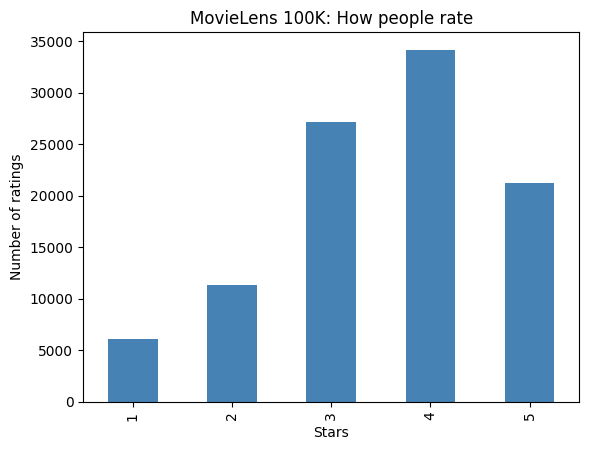

In [10]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
plt.show()

## Part C

Creates a matrix with the users as rows, movies as columns, and the ratings as the values within the matrix.

In [11]:
R = ratings.pivot_table(
    index="user",
    columns="item",
    values="rating"
)

R.shape returns the mxn shape of the ratings matrix, where the matrix has 943 rows (users) and 1682 columns (movies). fraction_missing is the percentage of missing reviews (empty entries in the matrix, where a specific user has not rated a specific movie).

In [12]:
print("Matrix shape:", R.shape)

fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing::", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing:: 0.937


ratings.groupby("user") groups all ratings belonging to a user for each user. Then, the size of that grouping is checked to determine the least active, median, and most active users. Then it prints the number of ratings the least active, median, and most active users have made.

In [13]:
per_user = ratings.groupby("user").size()

print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


# Part D

read in the movie information using vertical bars as the separator. The file has no header row. Keeps the first two columns that includes item and the title of the movie.

In [14]:
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)

Groups the ratings by movie and calculates each movie's number of ratings and average rating. Then uses "item" to attach each movie to its statistics. The sorts movies from most to fewest ratings and selects the first 5. Then displays the top 5 most rated movies with numbers rounded to 2 decimal places.

In [15]:
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))
top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


# Exercises

## Exercise 1



Q: **In the dummy matrix, identify all seven missing entries by user and movie. Give a predicted rating for each and justify two of your predictions using similar users or similar movies.**

A1: *Lily* did not provide a rating to **Backrooms**; however, given her dislike of horror-type movies, I predict she would give Backrooms a 2.5 rating.

A2: *Samuel* did not provide a rating to **The Odyssey**; however, given his higher ratings for action-like movies, I predict he would give The Odyssey a 4.5 rating.

A3: *Zoe* did not provide a rating to both **Project Hail Mary and Scream 7**; however, given her dislike and love for horror and action movies, respectively, I predict she would rate Project Hail Mary a 5.0 and Scream 7 a 1.5.

A4: *Paul* did not provide a rating to **Scream 7**; however, given his love for horror movies, I predict he would give Scream 7 a 4.5 rating.

A5: *Kameron* did not provide a rating to **Spider-Man: Brand New Day**; however, given his strong dislike of action movies and preference for horror, combined with Paul's rating trends, I predict he would rate Spider-Man: Brand New Day a 1.5.

A6: *Treasure* did not provide a rating to **Backrooms**; however, given his greater love for horror-type movies compared to action films, I predict he'd give Backrooms a 4.5 rating.






## Exercise 2

Q: Add a seventh imaginary user who likes action movies and dislikes romance movies. Choose
at least four ratings for this user, include two missing ratings, and explain what you would
predict for them.

In [16]:
users2 = ["Lily", "Samuel", "Zoe", "Paul", "Kameron", "Treasure", "John"]

New user named John likes action movies and dislikes horror movies.

In [17]:
dummy2 = np.array([
  [5, 4, 5, 3.1, np.nan, 2], # Lily
  [4, np.nan, 5, 2, 1, 1], # Samuel
  [5, 5, np.nan, 1, 2, np.nan], # Zoe
  [1, 2, 1, 5, 4, np.nan], # Paul
  [np.nan, 1, 2, 4, 5, 5], # Kameron
  [4, 2, 3, 5, np.nan, 4.3], # Treasure
  [5, 4, np.nan, 1, 2, np.nan], #John
])

In [18]:
dummy_table2 = pd.DataFrame(dummy2, index=users2, columns=movies)
dummy_table2

,Spider-Man: Brand New Day,The Odyssey,Project Hail Mary,Obsession,Backrooms,Scream 7
Lily,5.0,4.0,5.0,3.1,NaN,2.0
Samuel,4.0,NaN,5.0,2.0,1.0,1.0
Zoe,5.0,5.0,NaN,1.0,2.0,NaN
Paul,1.0,2.0,1.0,5.0,4.0,NaN
Kameron,NaN,1.0,2.0,4.0,5.0,5.0
Treasure,4.0,2.0,3.0,5.0,NaN,4.3
John,5.0,4.0,NaN,1.0,2.0,NaN


John has missing ratings for Project Hail Mary and Scream 7. I predict 5 stars for Project Hail Mary because John gives high ratings for action movies. I predict 1 star for Scream 7 because John gives lower ratings to horror movies.

## Exercise 3

Q: What does the command `np.isnan(dummy).sum()` compute? Write a different line of code that computes the fraction of missing entries in dummy.

In [21]:
total_nan_sum = np.isnan(dummy).sum()
total_nan_sum

np.int64(7)

`np.isnan(dummy).sum()` computes the number of missing entries in the dummy matrix.

In [22]:
round(total_nan_sum / dummy.size, 4)

np.float64(0.1944)

## Exercise 4

Q: Use the data frame ratings to find the least common star rating. State both the rating and
its number of occurrences.

In [24]:
ratings.value_counts().sort_values().head(1)

user  item  rating  time     
196   242   3       881250949    1
Name: count, dtype: int64

3 is the most common rating and it has occurred 881,250,949 times.

## Exercise 5

Q: Find the average rating for each user using groupby. Which user has the highest average
rating? Why should we be cautious about calling that person the “most positive” user?

In [26]:
ratings.groupby('user')['rating'].mean().sort_values(ascending=False)

user
849    4.869565
688    4.833333
507    4.724138
628    4.703704
928    4.687500
         ...   
774    2.058036
685    2.050000
445    1.985185
405    1.834464
181    1.491954
Name: rating, Length: 943, dtype: float64

User 849 has the highest average rating. This person might not be the "most positive" user because they could have only rated their favorite movies instead of all of the movies they have watched.

## Exercise 6

Q: In your own words, distinguish between the raw table ratings and the matrix R. What does
one row mean in each object?

The raw table ratings has one row per movie per user. It holds the user, the movie, the rating, and the time. The matrix R has one row per user. It holds the user's ratings for each of the movie columns.